In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests

print("Book Analytics is ready!")

Book Analytics is ready!


In [2]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import time

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
url = "https://books.toscrape.com/"

response = requests.get(url, timeout=20)
response.raise_for_status()

soup = BeautifulSoup(response.text, "html.parser")

books = soup.select("article.product_pod")

print("Website connection successful!")
print("Books found on this page:", len(books))
print("\nFirst book title:")
print(books[0].select_one("h3 a")["title"])

Website connection successful!
Books found on this page: 20

First book title:
A Light in the Attic


In [4]:
# Book Market Analytics
# Data Science 500 Assignment

import requests
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import time
from urllib.parse import urljoin

print("Libraries are ready!")

Libraries are ready!


In [5]:
url = "https://books.toscrape.com/"

response = requests.get(url, timeout=20)
response.raise_for_status()

soup = BeautifulSoup(response.content, "html.parser")

books = soup.select("article.product_pod")

print("Website status:", response.status_code)
print("Books found:", len(books))
print("First book:", books[0].select_one("h3 a")["title"])

Website status: 200
Books found: 20
First book: A Light in the Attic


In [6]:
# DATA ACQUISITION: Scrape Books to Scrape

base_url = "https://books.toscrape.com/"
current_url = base_url

all_books = []
pages_scraped = 0

while current_url:
    print("Scraping:", current_url)

    response = requests.get(current_url, timeout=20)
    response.raise_for_status()

    soup = BeautifulSoup(response.content, "html.parser")
    book_cards = soup.select("article.product_pod")

    for book in book_cards:
        # Book title
        title = book.select_one("h3 a")["title"]

        # Price in GBP
        price_text = book.select_one(".price_color").get_text(strip=True)
        price = float(
            price_text.replace("£", "").replace("Â", "")
        )

        # Star rating
        rating_element = book.select_one(".star-rating")
        rating = rating_element["class"][1]

        # Stock availability and quantity
        availability_text = book.select_one(
            ".availability"
        ).get_text(" ", strip=True)

        quantity_match = re.search(
            r"\((\d+)\s+available\)", availability_text
        )

        quantity = (
            int(quantity_match.group(1))
            if quantity_match else np.nan
        )

        stock_status = (
            "In stock"
            if "In stock" in availability_text
            else "Out of stock"
        )

        # Link to the individual book page
        relative_link = book.select_one("h3 a")["href"]
        product_url = urljoin(current_url, relative_link)

        all_books.append({
            "title": title,
            "price_gbp": price,
            "rating_word": rating,
            "stock_status": stock_status,
            "stock_quantity": quantity,
            "product_url": product_url
        })

    pages_scraped += 1

    # Find the next catalogue page
    next_link = soup.select_one("li.next a")

    if next_link:
        current_url = urljoin(current_url, next_link["href"])
        time.sleep(0.2)
    else:
        current_url = None

print("\nScraping complete!")
print("Pages scraped:", pages_scraped)
print("Books collected:", len(all_books))

Scraping: https://books.toscrape.com/
Scraping: https://books.toscrape.com/catalogue/page-2.html
Scraping: https://books.toscrape.com/catalogue/page-3.html
Scraping: https://books.toscrape.com/catalogue/page-4.html
Scraping: https://books.toscrape.com/catalogue/page-5.html
Scraping: https://books.toscrape.com/catalogue/page-6.html
Scraping: https://books.toscrape.com/catalogue/page-7.html
Scraping: https://books.toscrape.com/catalogue/page-8.html
Scraping: https://books.toscrape.com/catalogue/page-9.html
Scraping: https://books.toscrape.com/catalogue/page-10.html
Scraping: https://books.toscrape.com/catalogue/page-11.html
Scraping: https://books.toscrape.com/catalogue/page-12.html
Scraping: https://books.toscrape.com/catalogue/page-13.html
Scraping: https://books.toscrape.com/catalogue/page-14.html
Scraping: https://books.toscrape.com/catalogue/page-15.html
Scraping: https://books.toscrape.com/catalogue/page-16.html
Scraping: https://books.toscrape.com/catalogue/page-17.html
Scraping: 

In [7]:
books_df = pd.DataFrame(all_books)

print("Dataset shape:", books_df.shape)
display(books_df.head(10))

Dataset shape: (1000, 6)


,title,price_gbp,rating_word,stock_status,stock_quantity,product_url
0,A Light in the Attic,51.77,Three,In stock,NaN,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,One,In stock,NaN,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,One,In stock,NaN,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,Four,In stock,NaN,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,Five,In stock,NaN,https://books.toscrape.com/catalogue/sapiens-a...
5,The Requiem Red,22.65,One,In stock,NaN,https://books.toscrape.com/catalogue/the-requi...
6,The Dirty Little Secrets of Getting Your Dream...,33.34,Four,In stock,NaN,https://books.toscrape.com/catalogue/the-dirty...
7,The Coming Woman: A Novel Based on the Life of...,17.93,Three,In stock,NaN,https://books.toscrape.com/catalogue/the-comin...
8,The Boys in the Boat: Nine Americans and Their...,22.60,Four,In stock,NaN,https://books.toscrape.com/catalogue/the-boys-...
9,The Black Maria,52.15,One,In stock,NaN,https://books.toscrape.com/catalogue/the-black...


In [8]:
# Save the scraped books to a CSV file

books_df.to_csv("books_raw.csv", index=False)

print("Dataset saved successfully!")
print("Total books:", len(books_df))
print("Total columns:", len(books_df.columns))

Dataset saved successfully!
Total books: 1000
Total columns: 6


In [9]:
# Check the structure and data types

books_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   title           1000 non-null   str    
 1   price_gbp       1000 non-null   float64
 2   rating_word     1000 non-null   str    
 3   stock_status    1000 non-null   str    
 4   stock_quantity  0 non-null      float64
 5   product_url     1000 non-null   str    
dtypes: float64(2), str(4)
memory usage: 47.0 KB


In [10]:
# Check for missing values

print(books_df.isnull().sum())

title                0
price_gbp            0
rating_word          0
stock_status         0
stock_quantity    1000
product_url          0
dtype: int64


In [11]:
# STEP 8: DATA CLEANING

# Make a copy so we preserve the original scraped data
clean_df = books_df.copy()

# Convert star-rating words into numbers
rating_map = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

clean_df["rating"] = clean_df["rating_word"].map(rating_map)

# Remove duplicate book listings, if any
clean_df = clean_df.drop_duplicates(subset="product_url")

# Check for missing values
print("Dataset size:", clean_df.shape)
print("\nMissing values:")
print(clean_df.isnull().sum())

# Check for duplicate product URLs
print("\nDuplicate URLs:", clean_df["product_url"].duplicated().sum())

# Display the cleaned data
display(clean_df.head())

Dataset size: (1000, 7)

Missing values:
title                0
price_gbp            0
rating_word          0
stock_status         0
stock_quantity    1000
product_url          0
rating               0
dtype: int64

Duplicate URLs: 0


,title,price_gbp,rating_word,stock_status,stock_quantity,product_url,rating
0,A Light in the Attic,51.77,Three,In stock,NaN,https://books.toscrape.com/catalogue/a-light-i...,3
1,Tipping the Velvet,53.74,One,In stock,NaN,https://books.toscrape.com/catalogue/tipping-t...,1
2,Soumission,50.10,One,In stock,NaN,https://books.toscrape.com/catalogue/soumissio...,1
3,Sharp Objects,47.82,Four,In stock,NaN,https://books.toscrape.com/catalogue/sharp-obj...,4
4,Sapiens: A Brief History of Humankind,54.23,Five,In stock,NaN,https://books.toscrape.com/catalogue/sapiens-a...,5


In [12]:
# STEP 9: SCRAPE GENRES AND DESCRIPTIONS

genres = []
descriptions = []

for i, row in clean_df.iterrows():
    try:
        product_response = requests.get(
            row["product_url"],
            timeout=20
        )
        product_response.raise_for_status()

        product_soup = BeautifulSoup(
            product_response.content,
            "html.parser"
        )

        # Extract the book's genre from the breadcrumb
        breadcrumb_links = product_soup.select(
            "ul.breadcrumb li a"
        )

        if len(breadcrumb_links) >= 3:
            genre = breadcrumb_links[-1].get_text(strip=True)
        else:
            genre = np.nan

        # Extract the book description
        description_tag = product_soup.select_one(
            "#product_description + p"
        )

        if description_tag:
            description = description_tag.get_text(
                " ", strip=True
            )
        else:
            description = np.nan

    except requests.RequestException:
        genre = np.nan
        description = np.nan

    genres.append(genre)
    descriptions.append(description)

    # Show progress every 100 books
    if (i + 1) % 100 == 0:
        print(f"Processed {i + 1} books")

    time.sleep(0.2)

# Add the new columns
clean_df["genre"] = genres
clean_df["description"] = descriptions

print("\nGenre collection complete!")
print("Books:", len(clean_df))
print("Genres found:", clean_df["genre"].nunique())

Processed 100 books
Processed 200 books
Processed 300 books
Processed 400 books
Processed 500 books
Processed 600 books
Processed 700 books
Processed 800 books
Processed 900 books
Processed 1000 books

Genre collection complete!
Books: 1000
Genres found: 50


In [13]:
# STEP 10: SAVE THE CLEANED DATASET

clean_df.to_csv("books_clean.csv", index=False)

print("Clean dataset saved!")
print("Rows and columns:", clean_df.shape)

display(clean_df.head())

Clean dataset saved!
Rows and columns: (1000, 9)


,title,price_gbp,rating_word,stock_status,stock_quantity,product_url,rating,genre,description
0,A Light in the Attic,51.77,Three,In stock,NaN,https://books.toscrape.com/catalogue/a-light-i...,3,Poetry,It's hard to imagine a world without A Light i...
1,Tipping the Velvet,53.74,One,In stock,NaN,https://books.toscrape.com/catalogue/tipping-t...,1,Historical Fiction,"""Erotic and absorbing...Written with starling ..."
2,Soumission,50.10,One,In stock,NaN,https://books.toscrape.com/catalogue/soumissio...,1,Fiction,"Dans une France assez proche de la nôtre, un h..."
3,Sharp Objects,47.82,Four,In stock,NaN,https://books.toscrape.com/catalogue/sharp-obj...,4,Mystery,"WICKED above her hipbone, GIRL across her hear..."
4,Sapiens: A Brief History of Humankind,54.23,Five,In stock,NaN,https://books.toscrape.com/catalogue/sapiens-a...,5,History,From a renowned historian comes a groundbreaki...


In [14]:
# STEP 11: DATA QUALITY CHECKS

print("Missing values:")
print(clean_df.isnull().sum())

print("\nDuplicate books:", clean_df["product_url"].duplicated().sum())

print("\nBooks per genre:")
print(clean_df["genre"].value_counts().head(10))

print("\nSummary of numerical columns:")
display(clean_df[["price_gbp", "rating", "stock_quantity"]].describe())

Missing values:
title                0
price_gbp            0
rating_word          0
stock_status         0
stock_quantity    1000
product_url          0
rating               0
genre                0
description          2
dtype: int64

Duplicate books: 0

Books per genre:
genre
Default           152
Nonfiction        110
Sequential Art     75
Add a comment      67
Fiction            65
Young Adult        54
Fantasy            48
Romance            35
Mystery            32
Food and Drink     30
Name: count, dtype: int64

Summary of numerical columns:


,price_gbp,rating,stock_quantity
count,1000.00000,1000.000000,0.0
mean,35.07035,2.923000,NaN
std,14.44669,1.434967,NaN
min,10.00000,1.000000,NaN
25%,22.10750,2.000000,NaN
50%,35.98000,3.000000,NaN
75%,47.45750,4.000000,NaN
max,59.99000,5.000000,NaN


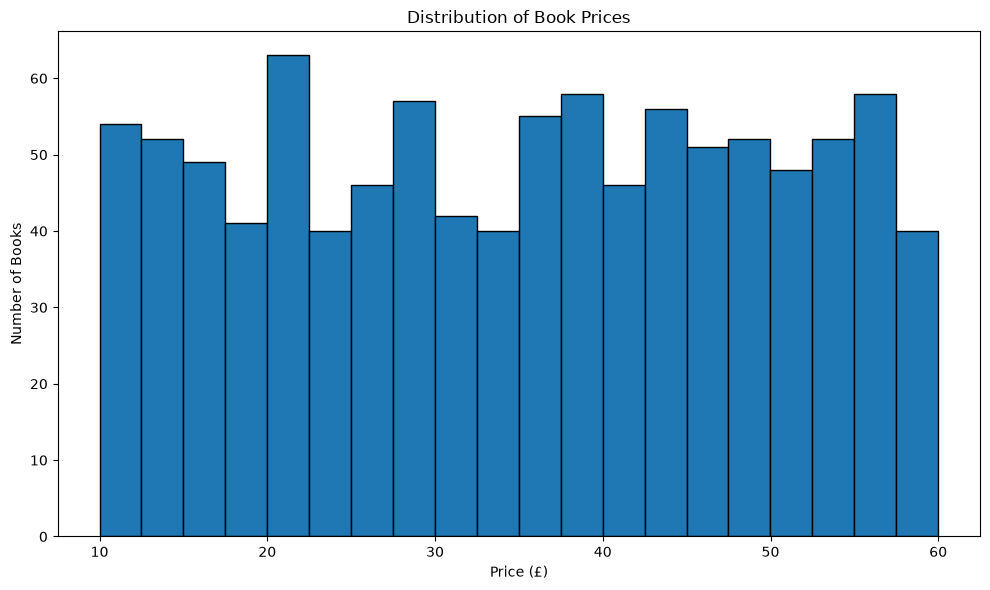

In [15]:
# STEP 13: PRICE DISTRIBUTION

plt.figure(figsize=(10, 6))

plt.hist(clean_df["price_gbp"], bins=20, edgecolor="black")

plt.title("Distribution of Book Prices")
plt.xlabel("Price (£)")
plt.ylabel("Number of Books")

plt.tight_layout()
plt.show()

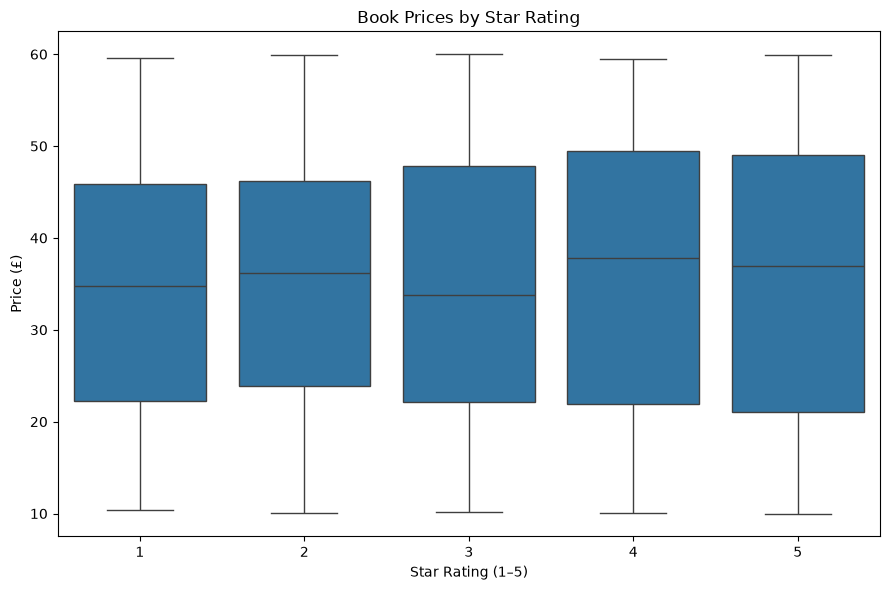

In [16]:
# STEP 14: PRICE BY STAR RATING

plt.figure(figsize=(9, 6))

sns.boxplot(data=clean_df, x="rating", y="price_gbp")

plt.title("Book Prices by Star Rating")
plt.xlabel("Star Rating (1–5)")
plt.ylabel("Price (£)")

plt.tight_layout()
plt.show()

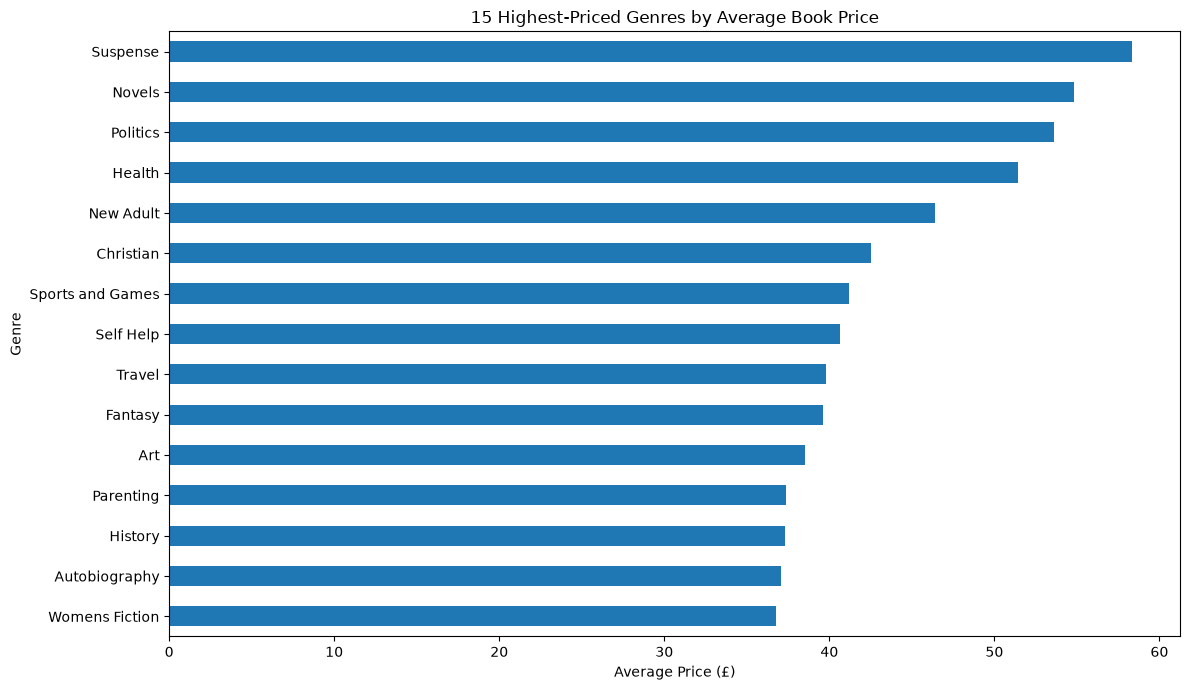

In [17]:
# STEP 15: AVERAGE PRICE BY GENRE

genre_prices = (
    clean_df.groupby("genre")["price_gbp"]
    .mean()
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(12, 7))

genre_prices.sort_values().plot(kind="barh")

plt.title("15 Highest-Priced Genres by Average Book Price")
plt.xlabel("Average Price (£)")
plt.ylabel("Genre")

plt.tight_layout()
plt.show()

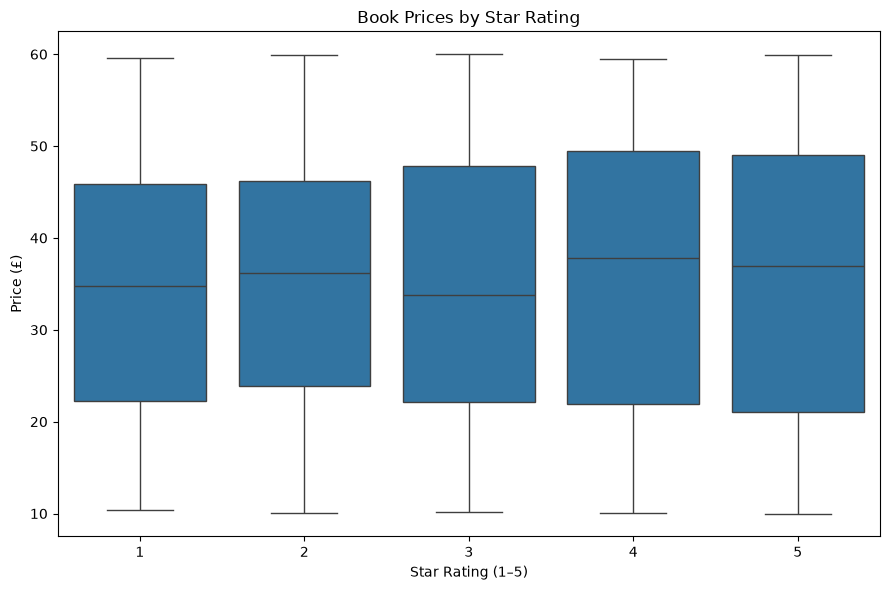

In [18]:
plt.figure(figsize=(9, 6))

sns.boxplot(data=clean_df, x="rating", y="price_gbp")

plt.title("Book Prices by Star Rating")
plt.xlabel("Star Rating (1–5)")
plt.ylabel("Price (£)")

plt.tight_layout()
plt.show()

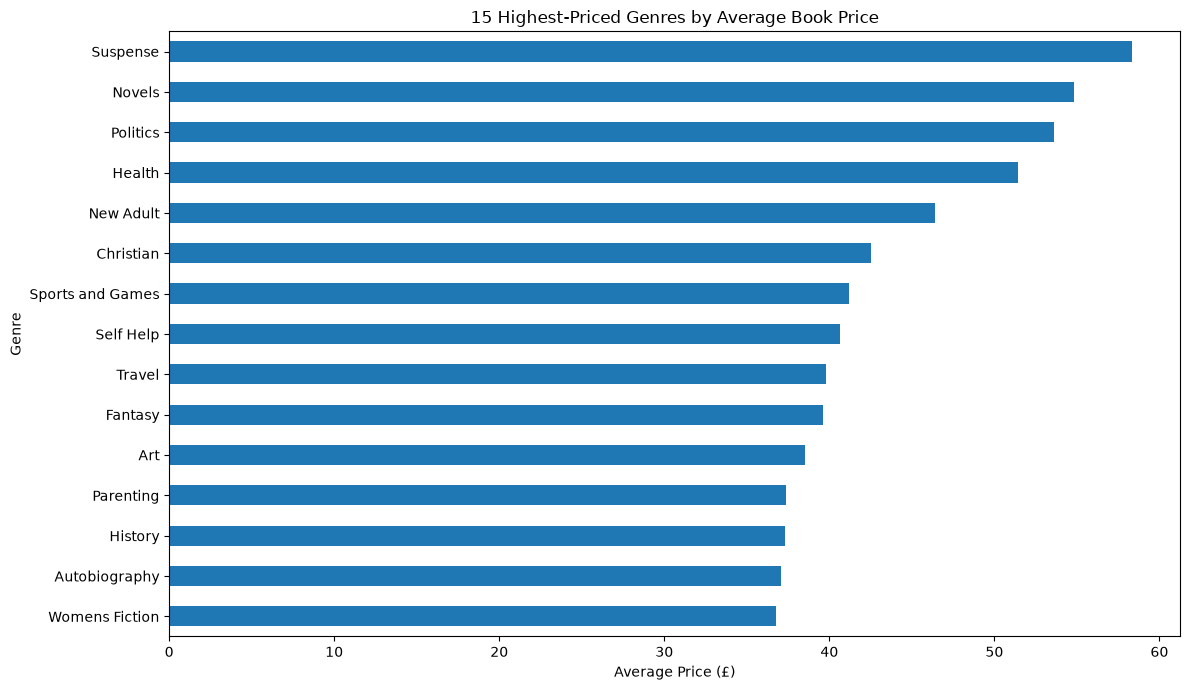

In [19]:
genre_prices = (
    clean_df.groupby("genre")["price_gbp"]
    .mean()
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(12, 7))

genre_prices.sort_values().plot(kind="barh")

plt.title("15 Highest-Priced Genres by Average Book Price")
plt.xlabel("Average Price (£)")
plt.ylabel("Genre")

plt.tight_layout()
plt.show()

In [20]:
clean_df.to_csv("books_clean.csv", index=False)

print("Updated dataset saved successfully!")
print("Total books:", len(clean_df))
print("Total genres:", clean_df["genre"].nunique())

Updated dataset saved successfully!
Total books: 1000
Total genres: 50


In [21]:
# Import tools for machine learning
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Select the columns needed for our model
model_df = clean_df[
    ["price_gbp", "rating", "stock_quantity", "stock_status", "genre"]
].copy()

# Fill missing values
model_df["stock_quantity"] = model_df["stock_quantity"].fillna(
    model_df["stock_quantity"].median()
)
model_df["genre"] = model_df["genre"].fillna("Unknown")
model_df["stock_status"] = model_df["stock_status"].fillna("Unknown")

# Remove rows without the target price or rating
model_df = model_df.dropna(subset=["price_gbp", "rating"])

# Convert categories such as genre and stock status into numbers
X = pd.get_dummies(
    model_df[["rating", "stock_quantity", "stock_status", "genre"]],
    columns=["stock_status", "genre"],
    drop_first=True,
    dtype=int
)

# The value we want the model to predict
y = model_df["price_gbp"]

print("Data preparation complete!")
print("Number of books:", len(model_df))
print("Number of input features:", X.shape[1])
print("Target variable: Book price (£)")

Data preparation complete!
Number of books: 1000
Number of input features: 51
Target variable: Book price (£)


In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape[0], "books")
print("Testing data:", X_test.shape[0], "books")

Training data: 800 books
Testing data: 200 books


In [26]:
print("X_train exists:", "X_train" in globals())
print("y_train exists:", "y_train" in globals())
print("X_test exists:", "X_test" in globals())
print("y_test exists:", "y_test" in globals())
print("LinearRegression exists:", "LinearRegression" in globals())

X_train exists: True
y_train exists: True
X_test exists: True
y_test exists: True
LinearRegression exists: True


In [27]:
print(X_train.shape)
print(y_train.shape)
print(X_train.dtypes.value_counts())
print(X_train.isnull().sum().sum())
print(y_train.isnull().sum())

(800, 51)
(800,)
int64      50
float64     1
Name: count, dtype: int64
800
0


In [28]:
try:
    model = LinearRegression()
    model.fit(X_train, y_train)
    print("Model trained successfully!")
except Exception as e:
    print("Error type:", type(e).__name__)
    print("Error message:", e)

Error type: ValueError
Error message: Input X contains NaN.
LinearRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values


In [29]:

# Evaluate the model's predictions

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, predictions)

print("MODEL EVALUATION RESULTS")
print("------------------------")
print(f"Mean Absolute Error (MAE): £{mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): £{rmse:.2f}")
print(f"R-squared (R²): {r2:.3f}")


NameError: name 'predictions' is not defined

In [30]:
predictions = model.predict(X_test)

print("Predictions created successfully!")
print(predictions[:5])

ValueError: Input X contains NaN.
LinearRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

In [31]:
try:
    predictions = model.predict(X_test)

    print("Predictions created successfully!")
    print(predictions[:5])

except Exception as e:
    print("Error type:", type(e).__name__)
    print("Error message:", e)

Error type: ValueError
Error message: Input X contains NaN.
LinearRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values


In [32]:
print("Training columns:", list(X_train.columns))
print("Testing columns:", list(X_test.columns))
print("Same columns:", list(X_train.columns) == list(X_test.columns))

Training columns: ['rating', 'stock_quantity', 'genre_Add a comment', 'genre_Adult Fiction', 'genre_Art', 'genre_Autobiography', 'genre_Biography', 'genre_Business', 'genre_Childrens', 'genre_Christian', 'genre_Christian Fiction', 'genre_Classics', 'genre_Contemporary', 'genre_Crime', 'genre_Cultural', 'genre_Default', 'genre_Erotica', 'genre_Fantasy', 'genre_Fiction', 'genre_Food and Drink', 'genre_Health', 'genre_Historical', 'genre_Historical Fiction', 'genre_History', 'genre_Horror', 'genre_Humor', 'genre_Music', 'genre_Mystery', 'genre_New Adult', 'genre_Nonfiction', 'genre_Novels', 'genre_Paranormal', 'genre_Parenting', 'genre_Philosophy', 'genre_Poetry', 'genre_Politics', 'genre_Psychology', 'genre_Religion', 'genre_Romance', 'genre_Science', 'genre_Science Fiction', 'genre_Self Help', 'genre_Sequential Art', 'genre_Short Stories', 'genre_Spirituality', 'genre_Sports and Games', 'genre_Suspense', 'genre_Thriller', 'genre_Travel', 'genre_Womens Fiction', 'genre_Young Adult']
Test

In [33]:
print("Model exists:", "model" in globals())
print("X_test exists:", "X_test" in globals())
print("Training columns:", X_train.shape[1])
print("Testing columns:", X_test.shape[1])
print("Same columns:", list(X_train.columns) == list(X_test.columns))

Model exists: True
X_test exists: True
Training columns: 51
Testing columns: 51
Same columns: True


In [34]:
try:
    print("Checking model...")
    print("Model exists:", "model" in globals())

    print("Checking test data...")
    print("X_test shape:", X_test.shape)

    print("Making predictions...")
    predictions = model.predict(X_test)

    print("Success! Predictions created.")
    print(predictions[:5])

except Exception as e:
    print("ERROR TYPE:", type(e).__name__)
    print("ERROR DETAILS:", repr(e))

Checking model...
Model exists: True
Checking test data...
X_test shape: (200, 51)
Making predictions...
ERROR TYPE: ValueError
ERROR DETAILS: ValueError('Input X contains NaN.\nLinearRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values')


In [35]:
print("Training data missing values:", X_train.isnull().sum().sum())
print("Testing data missing values:", X_test.isnull().sum().sum())

print("\nTraining data types:")
print(X_train.dtypes.value_counts())

print("\nTesting data types:")
print(X_test.dtypes.value_counts())

print("\nTraining columns:", X_train.shape[1])
print("Testing columns:", X_test.shape[1])
print("Columns match:", list(X_train.columns) == list(X_test.columns))

Training data missing values: 800
Testing data missing values: 200

Training data types:
int64      50
float64     1
Name: count, dtype: int64

Testing data types:
int64      50
float64     1
Name: count, dtype: int64

Training columns: 51
Testing columns: 51
Columns match: True


In [36]:
print("Missing values in training data:")
print(X_train.isnull().sum()[X_train.isnull().sum() > 0])

print("\nMissing values in testing data:")
print(X_test.isnull().sum()[X_test.isnull().sum() > 0])

Missing values in training data:
stock_quantity    800
dtype: int64

Missing values in testing data:
stock_quantity    200
dtype: int64


In [37]:
# Make a fresh copy of the model data
model_df = clean_df[
    ["price_gbp", "rating", "stock_quantity", "stock_status", "genre"]
].copy()

# Fill missing stock quantities using the median
median_stock = model_df["stock_quantity"].median()

if pd.isna(median_stock):
    model_df["stock_quantity"] = model_df["stock_quantity"].fillna(0)
else:
    model_df["stock_quantity"] = model_df["stock_quantity"].fillna(median_stock)

# Fill missing categories
model_df["genre"] = model_df["genre"].fillna("Unknown")
model_df["stock_status"] = model_df["stock_status"].fillna("Unknown")

# Remove rows missing price or rating
model_df = model_df.dropna(subset=["price_gbp", "rating"])

# Rebuild the input features and target
X = pd.get_dummies(
    model_df[["rating", "stock_quantity", "stock_status", "genre"]],
    columns=["stock_status", "genre"],
    drop_first=True,
    dtype=int
)

y = model_df["price_gbp"]

# Split the data again
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Missing values in X:", X.isnull().sum().sum())
print("Training books:", len(X_train))
print("Testing books:", len(X_test))

Missing values in X: 0
Training books: 800
Testing books: 200


In [38]:
model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Model retrained successfully!")
print("Predictions created:", len(predictions))
print(predictions[:5])

Model retrained successfully!
Predictions created: 200
[34.21703616 34.35740167 31.22347766 34.27278886 33.76658936]


In [39]:
mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, predictions)

print("MODEL EVALUATION RESULTS")
print("------------------------")
print(f"MAE: £{mae:.2f}")
print(f"MSE: {mse:.2f}")
print(f"RMSE: £{rmse:.2f}")
print(f"R-squared (R²): {r2:.3f}")

MODEL EVALUATION RESULTS
------------------------
MAE: £13.01
MSE: 231.02
RMSE: £15.20
R-squared (R²): -0.100


In [40]:
comparison = pd.DataFrame({
    "Actual Price (£)": y_test.values,
    "Predicted Price (£)": predictions
})

comparison["Difference (£)"] = (
    comparison["Actual Price (£)"] - comparison["Predicted Price (£)"]
).round(2)

display(comparison.head(10))

,Actual Price (£),Predicted Price (£),Difference (£)
0,11.38,34.217036,-22.84
1,20.93,34.357402,-13.43
2,33.92,31.223478,2.70
3,48.39,34.272789,14.12
4,20.50,33.766589,-13.27
5,26.77,32.703181,-5.93
6,16.96,34.357402,-17.40
7,20.90,34.582625,-13.68
8,36.17,36.960174,-0.79
9,24.12,34.332615,-10.21


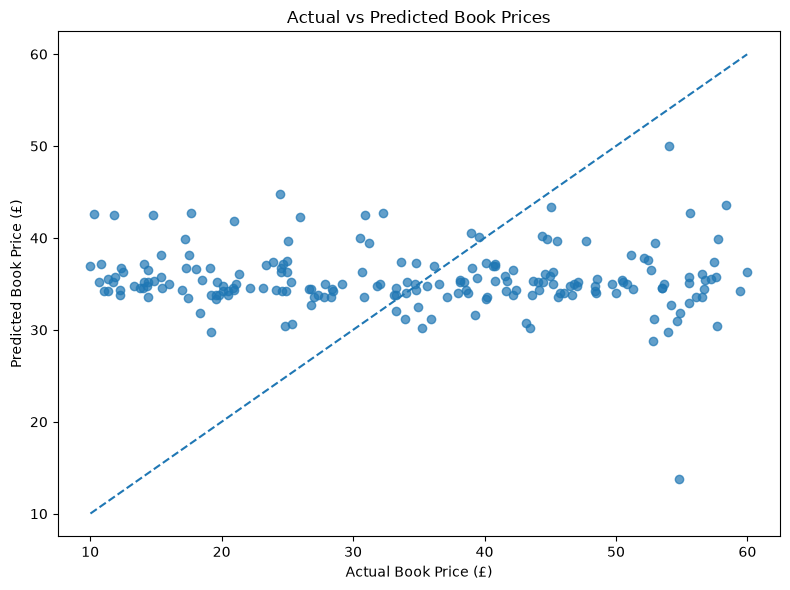

In [41]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, predictions, alpha=0.7)

plt.xlabel("Actual Book Price (£)")
plt.ylabel("Predicted Book Price (£)")
plt.title("Actual vs Predicted Book Prices")

# Reference line for perfect predictions
minimum = min(y_test.min(), predictions.min())
maximum = max(y_test.max(), predictions.max())
plt.plot([minimum, maximum], [minimum, maximum], linestyle="--")

plt.tight_layout()
plt.show()

In [42]:
clean_df.to_csv("books_clean.csv", index=False)

print("Clean dataset saved successfully!")
print("Total books:", len(clean_df))
print("Total genres:", clean_df["genre"].nunique())

Clean dataset saved successfully!
Total books: 1000
Total genres: 50


In [43]:
print("Total books scraped:", len(books_df))
print("Total books after cleaning:", len(clean_df))
print("Total genres:", clean_df["genre"].nunique())

Total books scraped: 1000
Total books after cleaning: 1000
Total genres: 50
